# Clean vs Injected Anomaly Data Visualization

This notebook visualizes the differences between clean (original) and injected anomaly samples from the pipeline test set (33 injected anomalies out of 1,652 test samples).

In [1]:
import sys
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

# Setup paths
PROJECT_ROOT = Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

# Import pipeline components
from src import config
from src.data_loader import load_data
from src import preprocessing as prep
from src.anomaly_injection import inject_anomalies
from src.autoencoder_model import train_detector

# Set style
sns.set_style('darkgrid')
plt.rcParams['figure.figsize'] = (16, 12)

# Reproducibility
np.random.seed(config.SEED)

# Load and preprocess data (same as pipeline)
print("Loading and preprocessing data (matching pipeline)...")
df = load_data("data/StudentPerformanceFactors.csv")
df = prep.handle_missing(df)
df_encoded, _ = prep.encode_categorical(df)
X_df, _ = prep.select_features(df_encoded)

# Split exactly like pipeline (75/25)
print("Splitting 75/25...")
X_train, X_test = train_test_split(X_df, test_size=config.TEST_SIZE, random_state=config.SEED)
print(f"Train samples: {len(X_train)}, Test samples: {len(X_test)}")

# Normalize exactly like pipeline
scaler, X_train_scaled = prep.normalize_features(X_train)
X_test_scaled = scaler.transform(X_test)

# Train autoencoder exactly like pipeline
print("Training autoencoder...")
model, _ = train_detector(
    X_train_scaled,
    contamination=config.INJECTION_FRAC,
    bottleneck_dim=config.BOTTLENECK_DIM,
    epochs=config.EPOCHS,
    batch_size=config.BATCH_SIZE,
    val_split=0.15,
    random_state=config.SEED,
)

# Inject anomalies exactly like pipeline (2% = 33 out of 1,652)
print(f"Injecting {config.INJECTION_FRAC:.0%} anomalies ({int(len(X_test_scaled) * config.INJECTION_FRAC)} samples)...")
X_test_inj_df, test_anom_idx = inject_anomalies(
    pd.DataFrame(X_test_scaled),
    method="noise",
    frac=config.INJECTION_FRAC,
    scale=config.NOISE_SCALE,
)
X_test_inj = X_test_inj_df.values

# Create binary labels (1=injected, 0=clean)
y_test = np.zeros(len(X_test_inj), dtype=int)
if test_anom_idx:
    y_test[np.array(test_anom_idx, dtype=int)] = 1

# Combine into dataframe for visualization
df_viz = pd.DataFrame(X_test_inj, columns=X_df.columns)
df_viz['injected'] = y_test

print(f"\n✓ ACTUAL PIPELINE DATA:")
print(f"  Total test samples: {len(df_viz)}")
print(f"  Clean samples: {(df_viz['injected'] == 0).sum()}")
print(f"  Injected samples: {(df_viz['injected'] == 1).sum()}")
print(f"  Expected: 1,619 clean + 33 injected = 1,652 total")
print(f"\nFirst few rows:")
print(df_viz.head())

# Use for all subsequent analysis
df = df_viz

Loading and preprocessing data (matching pipeline)...
Splitting 75/25...
Train samples: 4955, Test samples: 1652
Training autoencoder...
Injecting 2% anomalies (33 samples)...

✓ ACTUAL PIPELINE DATA:
  Total test samples: 1652
  Clean samples: 1619
  Injected samples: 33
  Expected: 1,619 clean + 33 injected = 1,652 total

First few rows:
   Hours_Studied  Attendance  Sleep_Hours  Previous_Scores  Tutoring_Sessions  \
0      -0.325067    0.521902     0.660932        -1.540523           2.839267   
1      -0.823480   -1.205916    -0.701630         1.045067           0.404838   
2       0.339484   -1.724261    -0.020349         1.673994          -0.406639   
3       2.000861    0.694684     0.660932        -1.191119           1.216314   
4      -1.820306    1.126638    -0.701630        -0.212787          -0.406639   

   Physical_Activity  Exam_Score  Parental_Involvement_Low  \
0           0.039264    0.189850                 -0.503781   
1           0.039264   -1.312874               

## 1. Feature-by-Feature Distribution Comparison

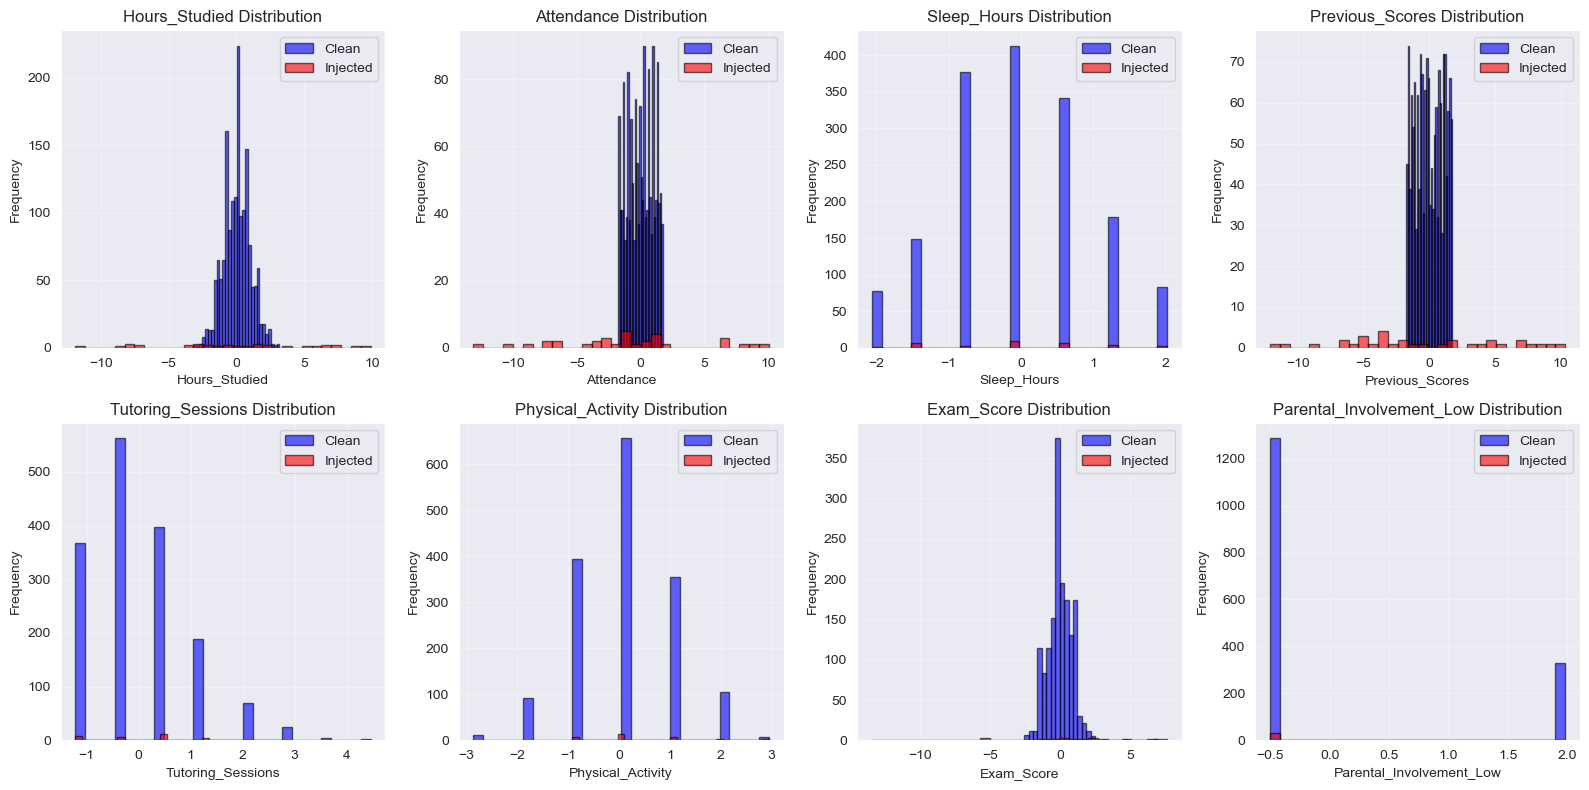

✓ Saved: clean_vs_injected_distributions.png


In [2]:
# Select key features for detailed comparison
numeric_features = df.columns[:-1].tolist()  # All except 'injected'
key_features = numeric_features[:8]  # First 8 features

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

clean_data = df[df['injected'] == 0]
injected_data = df[df['injected'] == 1]

for idx, feat in enumerate(key_features):
    ax = axes[idx]
    ax.hist(clean_data[feat], bins=30, alpha=0.6, label='Clean', color='blue', edgecolor='black')
    ax.hist(injected_data[feat], bins=30, alpha=0.6, label='Injected', color='red', edgecolor='black')
    ax.set_xlabel(feat, fontsize=10)
    ax.set_ylabel('Frequency')
    ax.set_title(f'{feat} Distribution')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('outputs/clean_vs_injected_distributions.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: clean_vs_injected_distributions.png")

## 2. PCA 2D Projection

PCA Explained Variance:
  PC1: 7.1%
  PC2: 6.5%
  Total: 13.7%


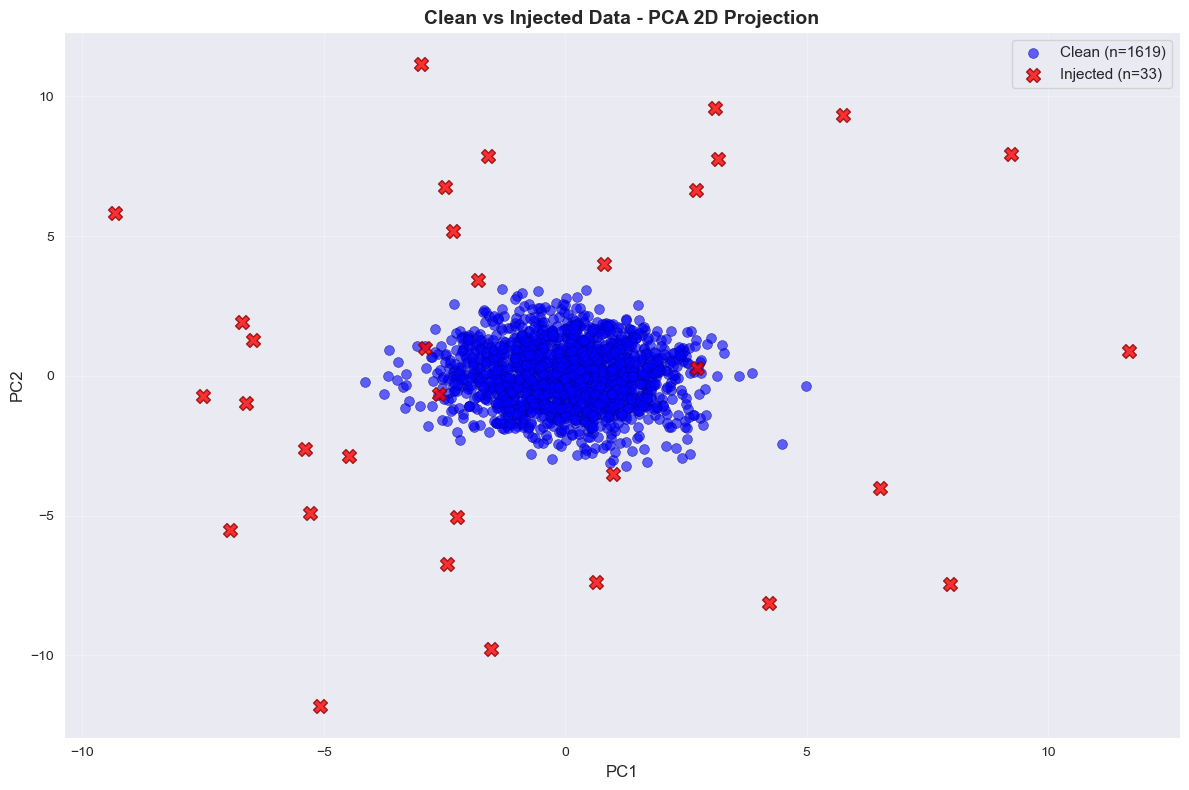

✓ Saved: pca_clean_vs_injected.png


In [3]:
# Prepare data for PCA
X = df.drop('injected', axis=1).values
y = df['injected'].values

# Apply PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

print(f"PCA Explained Variance:")
print(f"  PC1: {pca.explained_variance_ratio_[0]:.1%}")
print(f"  PC2: {pca.explained_variance_ratio_[1]:.1%}")
print(f"  Total: {pca.explained_variance_ratio_.sum():.1%}")

# Plot
fig, ax = plt.subplots(figsize=(12, 8))

# Clean samples
clean_mask = y == 0
ax.scatter(X_pca[clean_mask, 0], X_pca[clean_mask, 1], 
          c='blue', alpha=0.6, s=50, label=f'Clean (n={clean_mask.sum()})', edgecolors='darkblue', linewidth=0.5)

# Injected samples
injected_mask = y == 1
ax.scatter(X_pca[injected_mask, 0], X_pca[injected_mask, 1], 
          c='red', alpha=0.8, s=100, label=f'Injected (n={injected_mask.sum()})', edgecolors='darkred', linewidth=1, marker='X')

ax.set_xlabel(f'PC1', fontsize=12)
ax.set_ylabel(f'PC2', fontsize=12)
ax.set_title('Clean vs Injected Data - PCA 2D Projection', fontsize=14, fontweight='bold')
ax.legend(fontsize=11, loc='best')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('outputs/pca_clean_vs_injected.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: pca_clean_vs_injected.png")

## 3. Box Plot Comparison

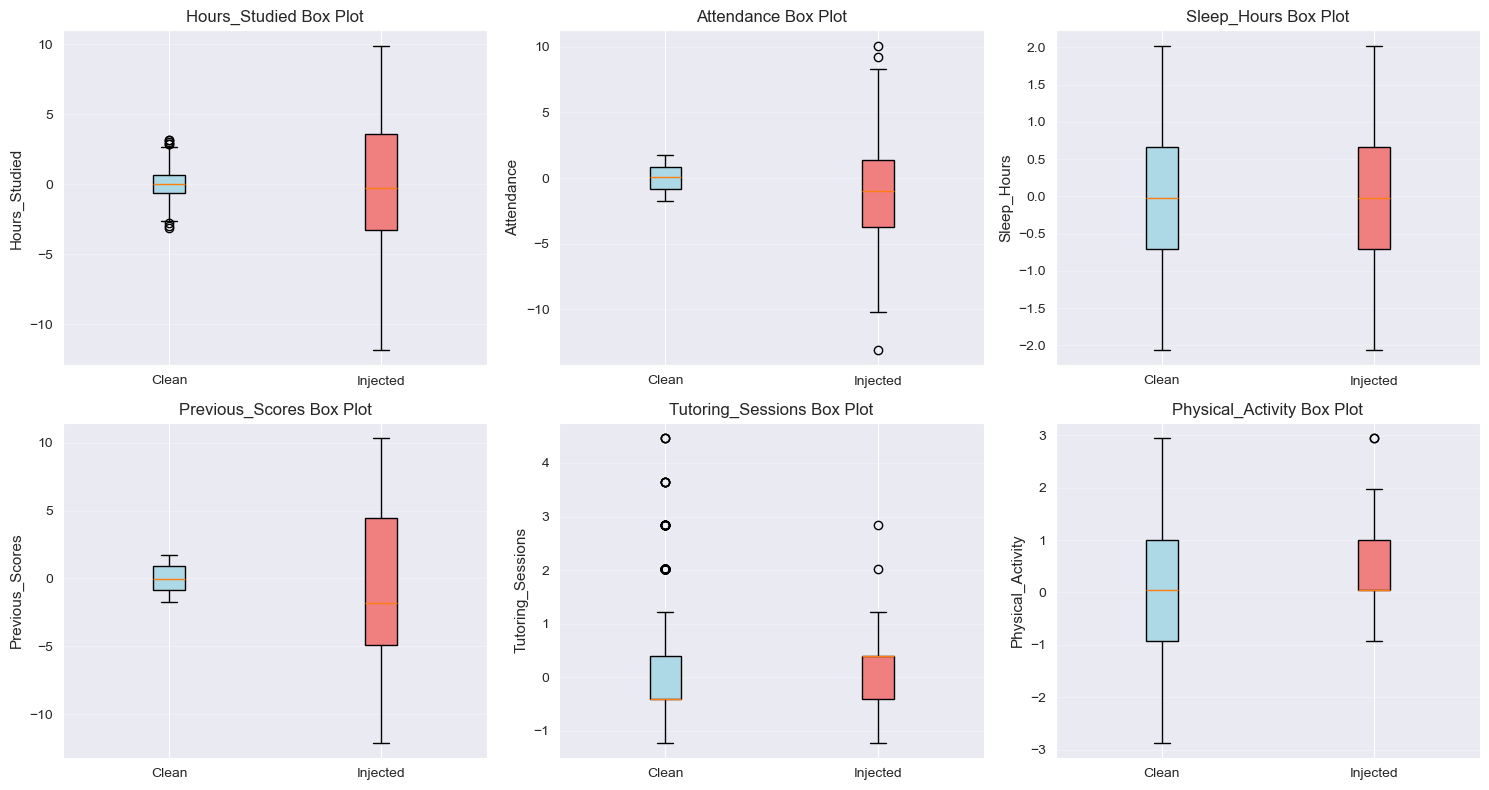

✓ Saved: boxplot_clean_vs_injected.png


In [4]:
# Select top features for box plots
top_features = numeric_features[:6]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for idx, feat in enumerate(top_features):
    ax = axes[idx]
    data_to_plot = [df[df['injected'] == 0][feat], df[df['injected'] == 1][feat]]
    bp = ax.boxplot(data_to_plot, labels=['Clean', 'Injected'], patch_artist=True)
    
    # Color boxes
    colors = ['lightblue', 'lightcoral']
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
    
    ax.set_ylabel(feat, fontsize=11)
    ax.set_title(f'{feat} Box Plot')
    ax.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('outputs/boxplot_clean_vs_injected.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: boxplot_clean_vs_injected.png")

## 4. Statistical Summary Table

In [5]:
# Compute statistics for each feature
stats = []

for feat in numeric_features[:10]:  # First 10 features
    clean_vals = df[df['injected'] == 0][feat]
    inj_vals = df[df['injected'] == 1][feat]
    
    # Calculate difference metrics
    mean_diff = abs(clean_vals.mean() - inj_vals.mean())
    std_clean = clean_vals.std()
    std_inj = inj_vals.std()
    
    stats.append({
        'Feature': feat,
        'Clean Mean': f"{clean_vals.mean():.3f}",
        'Inject Mean': f"{inj_vals.mean():.3f}",
        'Mean Δ': f"{mean_diff:.3f}",
        'Clean Std': f"{std_clean:.3f}",
        'Inject Std': f"{std_inj:.3f}",
    })

stats_df = pd.DataFrame(stats)
print("\n" + "="*90)
print("STATISTICAL COMPARISON: Clean vs Injected Data")
print("="*90)
print(stats_df.to_string(index=False))
print("="*90)


STATISTICAL COMPARISON: Clean vs Injected Data
                    Feature Clean Mean Inject Mean Mean Δ Clean Std Inject Std
              Hours_Studied      0.015      -0.316  0.332     0.983      5.655
                 Attendance      0.004      -0.942  0.946     0.989      5.592
                Sleep_Hours     -0.003       0.042  0.045     0.998      1.134
            Previous_Scores      0.003      -0.509  0.512     1.024      6.061
          Tutoring_Sessions     -0.027       0.110  0.136     0.993      1.031
          Physical_Activity      0.026       0.303  0.277     0.990      1.062
                 Exam_Score     -0.008      -0.097  0.089     0.895      5.005
   Parental_Involvement_Low      0.005      -0.278  0.283     1.004      0.727
Parental_Involvement_Medium      0.025       0.262  0.238     1.000      0.977
    Access_to_Resources_Low     -0.037      -0.203  0.166     0.972      0.824


## 5. Feature Value Heatmap (Sample Comparison)

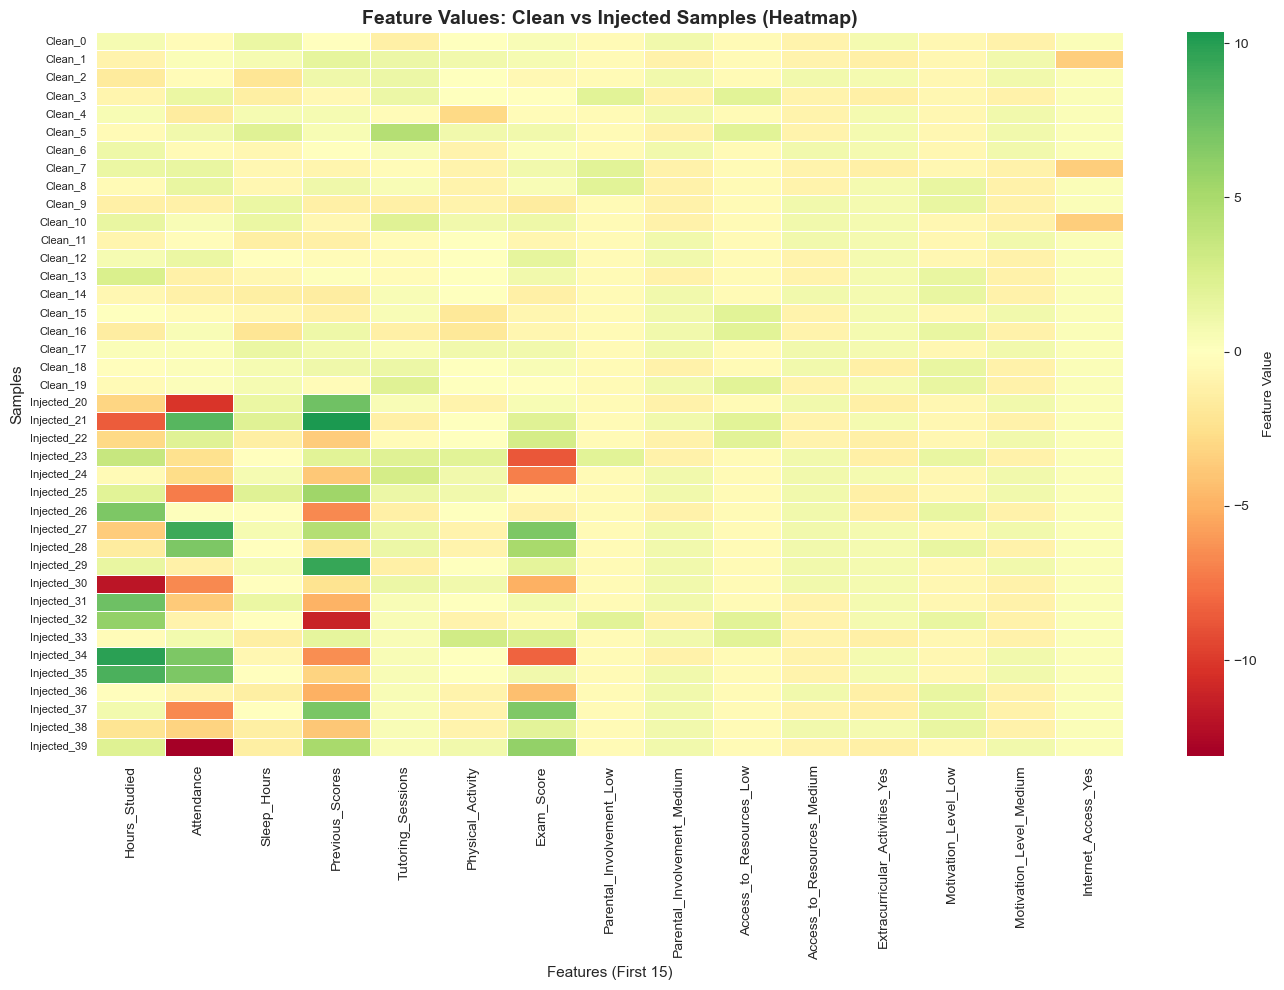

✓ Saved: heatmap_clean_vs_injected.png


In [6]:
# Create heatmap showing samples
# Take random samples from each group
np.random.seed(41)

clean_samples = df[df['injected'] == 0].sample(n=min(20, len(df[df['injected'] == 0])), random_state=42)
injected_samples = df[df['injected'] == 1].sample(n=min(20, len(df[df['injected'] == 1])), random_state=42)

# Combine and keep only features (drop injected column)
heatmap_data = pd.concat([
    clean_samples.drop('injected', axis=1),
    injected_samples.drop('injected', axis=1)
])

# Create labels
labels = ['Clean'] * len(clean_samples) + ['Injected'] * len(injected_samples)

# Plot heatmap (first 15 features for visibility)
fig, ax = plt.subplots(figsize=(14, 10))

sns.heatmap(heatmap_data.iloc[:, :15], cmap='RdYlGn', center=0, 
            cbar_kws={'label': 'Feature Value'}, ax=ax, linewidths=0.5)

# Add labels on left side
ax.set_yticklabels([f"{label}_{i}" for i, label in enumerate(labels)], fontsize=8)
ax.set_title('Feature Values: Clean vs Injected Samples (Heatmap)', fontsize=14, fontweight='bold')
ax.set_xlabel('Features (First 15)', fontsize=11)
ax.set_ylabel('Samples', fontsize=11)

plt.tight_layout()
plt.savefig('outputs/heatmap_clean_vs_injected.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: heatmap_clean_vs_injected.png")

## 6. Violation Analysis - What Changed?

In [7]:
# Calculate the magnitude of change for each injected sample
# For each injected sample, find its closest clean sample and calculate feature-wise differences

from scipy.spatial.distance import cdist

clean_X = df[df['injected'] == 0].drop('injected', axis=1).values
injected_X = df[df['injected'] == 1].drop('injected', axis=1).values

# Calculate average change magnitude per feature
avg_changes = []
feature_names = df.drop('injected', axis=1).columns.tolist()

# Compare each injected sample with the closest clean sample
distances = cdist(injected_X, clean_X, metric='euclidean')
closest_clean_idx = np.argmin(distances, axis=1)

for feat_idx, feat_name in enumerate(feature_names):
    differences = []
    for inj_idx in range(len(injected_X)):
        clean_idx = closest_clean_idx[inj_idx]
        diff = abs(injected_X[inj_idx, feat_idx] - clean_X[clean_idx, feat_idx])
        differences.append(diff)
    avg_changes.append(np.mean(differences))

# Sort by magnitude
sorted_features = sorted(zip(feature_names, avg_changes), key=lambda x: x[1], reverse=True)

print("\n" + "="*70)
print("TOP FEATURES MOST AFFECTED BY ANOMALY INJECTION")
print("="*70)
print(f"{'Rank':<5} {'Feature':<35} {'Avg Change':>15}")
print("-"*70)
for rank, (feat, change) in enumerate(sorted_features[:15], 1):
    print(f"{rank:<5} {feat:<35} {change:>15.4f}")
print("="*70)


TOP FEATURES MOST AFFECTED BY ANOMALY INJECTION
Rank  Feature                                  Avg Change
----------------------------------------------------------------------
1     Previous_Scores                              4.0193
2     Hours_Studied                                3.7128
3     Attendance                                   3.6915
4     Exam_Score                                   3.0709
5     Sleep_Hours                                  0.9497
6     Physical_Activity                            0.8506
7     Tutoring_Sessions                            0.7377
8     Gender_Male                                  0.7363
9     School_Type_Public                           0.7259
10    Distance_from_Home_Near                      0.6794
11    Access_to_Resources_Medium                   0.6667
12    Parental_Involvement_Medium                  0.5455
13    Motivation_Level_Medium                      0.4849
14    Teacher_Quality_Medium                       0.4328
15    Fami

## 7. Feature Importance - Top Affected Features Visualization

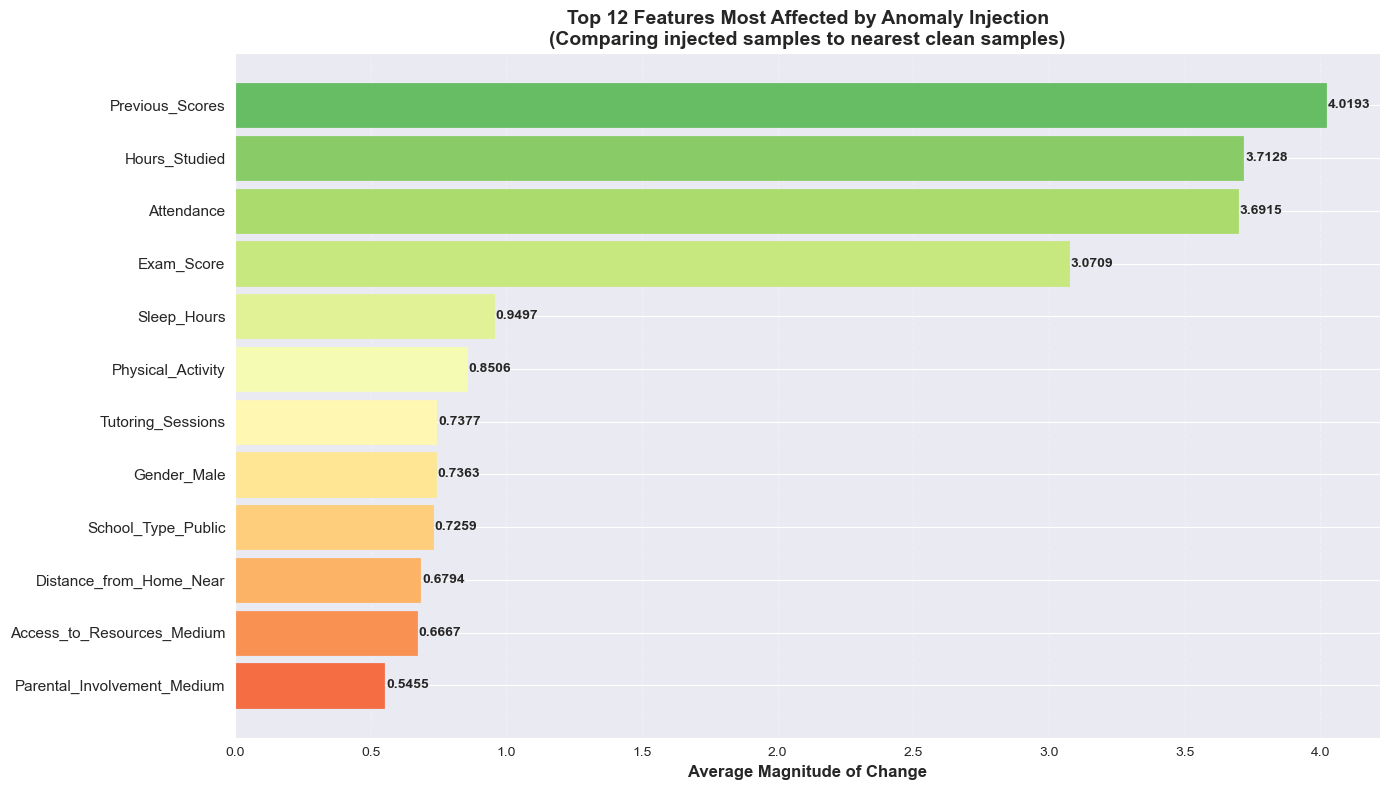

✓ Saved: top_affected_features.png

FEATURE IMPORTANCE SUMMARY

Most affected feature: Previous_Scores
  Average change magnitude: 4.0193

Least affected (in top 12): Parental_Involvement_Medium
  Average change magnitude: 0.5455

INTERPRETATION:
Features with HIGHER change magnitudes are more susceptible to the
anomaly injection method (Gaussian noise). These are the features that
are most 'violated' when anomalies are injected, making them valuable
for anomaly detection via reconstruction error in the autoencoder.


In [8]:
# Visualize top affected features
top_n = 12
top_features_list = [f[0] for f in sorted_features[:top_n]]
top_changes = [f[1] for f in sorted_features[:top_n]]

fig, ax = plt.subplots(figsize=(14, 8))
bars = ax.barh(range(len(top_features_list)), top_changes, color='steelblue', edgecolor='darkblue', linewidth=2)

# Color bars by magnitude (gradient effect)
colors = plt.cm.RdYlGn_r(np.linspace(0.2, 0.8, len(bars)))
for bar, color in zip(bars, colors):
    bar.set_color(color)

ax.set_yticks(range(len(top_features_list)))
ax.set_yticklabels(top_features_list, fontsize=11)
ax.set_xlabel('Average Magnitude of Change', fontsize=12, fontweight='bold')
ax.set_title(f'Top {top_n} Features Most Affected by Anomaly Injection\n(Comparing injected samples to nearest clean samples)', 
             fontsize=14, fontweight='bold')
ax.grid(alpha=0.3, axis='x', linestyle='--')
ax.invert_yaxis()

# Add value labels on bars
for i, (bar, val) in enumerate(zip(bars, top_changes)):
    ax.text(val + 0.01, i, f'{val:.4f}', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('outputs/top_affected_features.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: top_affected_features.png")

# Summary
print("\n" + "="*70)
print("FEATURE IMPORTANCE SUMMARY")
print("="*70)
print(f"\nMost affected feature: {sorted_features[0][0]}")
print(f"  Average change magnitude: {sorted_features[0][1]:.4f}")
print(f"\nLeast affected (in top 12): {sorted_features[top_n-1][0]}")
print(f"  Average change magnitude: {sorted_features[top_n-1][1]:.4f}")
print("\n" + "="*70)
print("INTERPRETATION:")
print("="*70)
print("Features with HIGHER change magnitudes are more susceptible to the")
print("anomaly injection method (Gaussian noise). These are the features that")
print("are most 'violated' when anomalies are injected, making them valuable")
print("for anomaly detection via reconstruction error in the autoencoder.")
print("="*70)

## 8. Reconstruction Error Separation Analysis

Computing reconstruction errors...
Clean error (mean): 0.506
Injected error (mean): 4.559


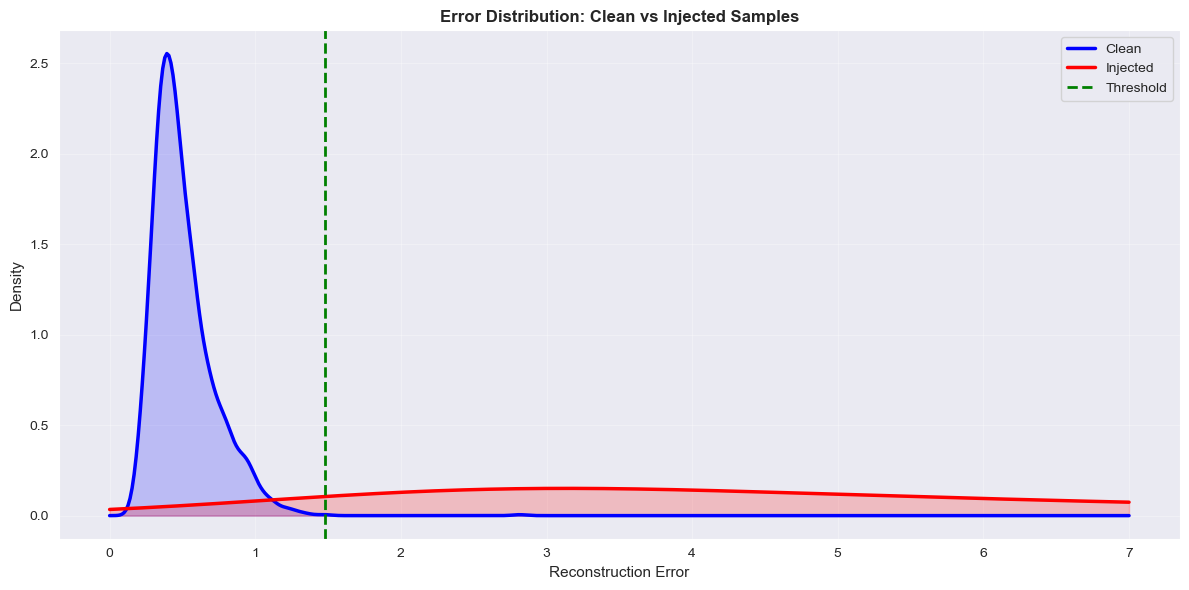


✓ Saved: error_separation_curves.png


In [9]:
from scipy.stats import gaussian_kde

# Calculate reconstruction errors
print("Computing reconstruction errors...")
X_reconstructed = model.predict(X_test_inj, verbose=0)
reconstruction_errors = np.mean((X_test_inj - X_reconstructed) ** 2, axis=1)

# Separate by class
clean_errors = reconstruction_errors[y_test == 0]
injected_errors = reconstruction_errors[y_test == 1]

print(f"Clean error (mean): {clean_errors.mean():.3f}")
print(f"Injected error (mean): {injected_errors.mean():.3f}")

# Create smooth curves using KDE
kde_clean = gaussian_kde(clean_errors)
kde_injected = gaussian_kde(injected_errors)

x_range = np.linspace(0, 7, 500)
density_clean = kde_clean(x_range)
density_injected = kde_injected(x_range)

# Simple visualization
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(x_range, density_clean, linewidth=2.5, label='Clean', color='blue')
ax.plot(x_range, density_injected, linewidth=2.5, label='Injected', color='red')

ax.fill_between(x_range, density_clean, alpha=0.2, color='blue')
ax.fill_between(x_range, density_injected, alpha=0.2, color='red')

# Threshold line
ax.axvline(1.476, color='green', linestyle='--', linewidth=2, label='Threshold')

ax.set_xlabel('Reconstruction Error', fontsize=11)
ax.set_ylabel('Density', fontsize=11)
ax.set_title('Error Distribution: Clean vs Injected Samples', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('outputs/error_separation_curves.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Saved: error_separation_curves.png")